# Neural Networks with One Hidden Layer — worked study copy

Answers prepared for revision with AI assistance. IBM / Skills Network source notices and embedded instructor explanations are retained. This is not a course submission.

Code completion and execution are tracked separately in the [solution progress report](../../../docs/SOLUTION_PROGRESS.md). Training may require a separate environment, external data, compute or provider credentials.

[Original reference](../../../courses/05-deep-learning-with-pytorch/notebooks/neural-networks-with-one-hidden-layer.ipynb) · [Course notes](../../../courses/05-deep-learning-with-pytorch/README.md)

**BOUNDED SMOKE RUN:** seed 42; CSVs sampled to at most 5,000 rows; one grid setting with two folds; training budgets capped; DataLoaders limited to 12 batches. These outputs are execution checks, not full-run model evaluations.

In [1]:
import os, itertools, random
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['TF_NUM_INTEROP_THREADS'] = '1'
os.environ['TF_NUM_INTRAOP_THREADS'] = '1'
import numpy as np
np.random.seed(42)
random.seed(42)
import pandas as pd
_read_csv = pd.read_csv
def _bounded_csv(*args, **kwargs):
    data = _read_csv(*args, **kwargs)
    return data.sample(n=5000,random_state=42) if len(data)>5000 else data
pd.read_csv = _bounded_csv
from sklearn.model_selection import GridSearchCV
_grid_fit = GridSearchCV.fit
def _bounded_grid(self, *args, **kwargs):
    grids = self.param_grid if isinstance(self.param_grid,list) else [self.param_grid]
    self.param_grid = [{k:list(v)[:1] for k,v in grid.items()} for grid in grids[:1]]
    self.cv = 2
    self.n_jobs = 1
    self.verbose = 0
    return _grid_fit(self,*args,**kwargs)
GridSearchCV.fit = _bounded_grid
try:
    import torch
except ImportError:
    torch = None
if torch is not None:
    torch.manual_seed(42)
    torch.set_num_threads(1)
    _loader_iter = torch.utils.data.DataLoader.__iter__
    def _bounded_loader(self):
        return itertools.islice(_loader_iter(self),12)
    torch.utils.data.DataLoader.__iter__ = _bounded_loader


<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


<h1>Neural Networks with One Hidden Layer</h1>


**Estimated time needed**: 25 minutes


## Learning Objectives
After completing this lab, you will be able to:
- Classify handwritten digits using Neural Network 


<h2>Table of Contents</h2>
<p>In this lab, you will use a single layer neural network to classify handwritten digits from the MNIST database.</p>

<ol>
<li><a href="#Import-the-Libraries">Import the Libraries</a> 
</li>
<li><a href="#Neural-Network-Module-and-the-Training-Function">Neural Network Module and the Training Function</a>  
</li>
<li><a href="#Create-some-Data">Create some Data</a>     
</li>
<li><a href="#Define-the-Neural-Network-and-Optimizer">Define the Neural Network and Optimizer</a>     
</li>
<li><a href="#Analyze-the-Results">Analyze the Results</a>
</li>
<li><a href="#Practice:-Recreate-the-Model-with-nn.Sequential">Practice: Recreate the Model with nn.Sequential</a>
</li>    
</ol>

<hr>


## Import the Libraries


We'll need the following libraries


In [2]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torchvision.datasets as dsets
import torch.nn.functional as F
import matplotlib.pylab as plt
import numpy as np

Matplotlib is building the font cache; this may take a moment.


Use the following helper functions for plotting the loss: 


In [3]:
def plot_accuracy_loss(training_results):
    plt.subplot(2, 1, 1)
    plt.plot(training_results['training_loss'], 'r')
    plt.ylabel('loss')
    plt.title('training loss iterations')
    plt.subplot(2, 1, 2)
    plt.plot(training_results['validation_accuracy'])
    plt.ylabel('accuracy')
    plt.xlabel('epochs')
    plt.show()

Use the following function for printing the model parameters: 


In [4]:
def print_model_parameters(model):
    count = 0
    for ele in model.state_dict():
        count += 1
        if count % 2 != 0:
            print('The following are the parameters for the layer ', count // 2 + 1)
        if ele.find('bias') != -1:
            print('The size of bias: ', model.state_dict()[ele].size())
        else:
            print('The size of weights: ', model.state_dict()[ele].size())

Define the neural network module or class: 


In [5]:
def show_data(data_sample):
    plt.imshow(data_sample.numpy().reshape(28, 28), cmap='gray')
    plt.show()

<!--Empty Space for separating topics-->


## Neural Network Module and the Training Function


Define the neural network module or class: 


In [6]:
class Net(nn.Module):

    def __init__(self, D_in, H, D_out):
        super(Net, self).__init__()
        self.linear1 = nn.Linear(D_in, H)
        self.linear2 = nn.Linear(H, D_out)

    def forward(self, x):
        x = torch.sigmoid(self.linear1(x))
        x = self.linear2(x)
        return x

Define a function to train the model. In this case, the function returns a Python dictionary to store the training loss and accuracy on the validation data. 


In [7]:
def train(model, criterion, train_loader, validation_loader, optimizer, epochs=2):
    i = 0
    useful_stuff = {'training_loss': [], 'validation_accuracy': []}
    for epoch in itertools.islice(range(epochs), 2):
        for i, (x, y) in enumerate(train_loader):
            optimizer.zero_grad()
            z = model(x.view(-1, 28 * 28))
            loss = criterion(z, y)
            loss.backward()
            optimizer.step()
            useful_stuff['training_loss'].append(loss.data.item())
        correct = 0
        for x, y in validation_loader:
            z = model(x.view(-1, 28 * 28))
            _, label = torch.max(z, 1)
            correct += (label == y).sum().item()
        accuracy = 100 * (correct / len(validation_dataset))
        useful_stuff['validation_accuracy'].append(accuracy)
    return useful_stuff

<!--Empty Space for separating topics-->


## Create some Data


Load the training dataset by setting the parameters <code>train</code> to <code>True</code> and convert it to a tensor by placing a transform object in the argument <code>transform</code>.


In [8]:
train_dataset = dsets.MNIST(root='./data', train=True, download=True, transform=transforms.ToTensor())

  0%|          | 0.00/9.91M [00:00<?, ?B/s]

  0%|          | 32.8k/9.91M [00:00<00:50, 198kB/s]

  1%|          | 98.3k/9.91M [00:00<00:32, 303kB/s]

  2%|▏         | 197k/9.91M [00:00<00:21, 442kB/s] 

  4%|▍         | 393k/9.91M [00:00<00:12, 761kB/s]

  7%|▋         | 688k/9.91M [00:00<00:06, 1.32MB/s]

... (29 outputs left out)

 93%|█████████▎| 1.54M/1.65M [00:01<00:00, 1.24MB/s]

100%|██████████| 1.65M/1.65M [00:01<00:00, 906kB/s] 

  0%|          | 0.00/4.54k [00:00<?, ?B/s]

100%|██████████| 4.54k/4.54k [00:00<00:00, 239kB/s]

Load the testing dataset and convert it to a tensor by placing a transform object in the argument <code>transform</code>:


In [9]:
validation_dataset = dsets.MNIST(root='./data', download=True, transform=transforms.ToTensor())

Create the criterion function:  


In [10]:
criterion = nn.CrossEntropyLoss()

Create the training-data loader and the validation-data loader objects: 


In [11]:
train_loader = torch.utils.data.DataLoader(dataset=train_dataset, batch_size=2000, shuffle=True)
validation_loader = torch.utils.data.DataLoader(dataset=validation_dataset, batch_size=5000, shuffle=False)

<!--Empty Space for separating topics-->


## Define the Neural Network and Optimizer


Create the model with 100 neurons: 


In [12]:
input_dim = 28 * 28
hidden_dim = 100
output_dim = 10
model = Net(input_dim, hidden_dim, output_dim)

Print the model parameters: 


In [13]:
print_model_parameters(model)

The following are the parameters for the layer  1
The size of weights:  torch.Size([100, 784])
The size of bias:  torch.Size([100])
The following are the parameters for the layer  2
The size of weights:  torch.Size([10, 100])
The size of bias:  torch.Size([10])


Define the optimizer object with a learning rate of 0.01: 


In [14]:
learning_rate = 0.01
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

Train the model by using 100 epochs **(this process takes time)**: 


In [15]:
training_results = train(model, criterion, train_loader, validation_loader, optimizer, epochs=2)

<!--Empty Space for separating topics-->


## Analyze the Results


Plot the training total loss or cost for every iteration and plot the training accuracy for every epoch:  


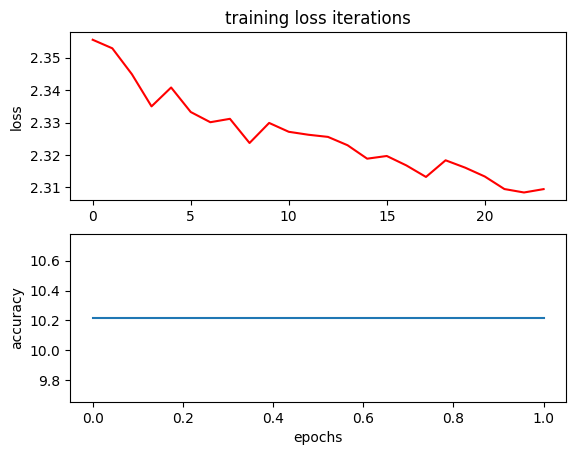

In [16]:
plot_accuracy_loss(training_results)

Plot the first five misclassified samples:   


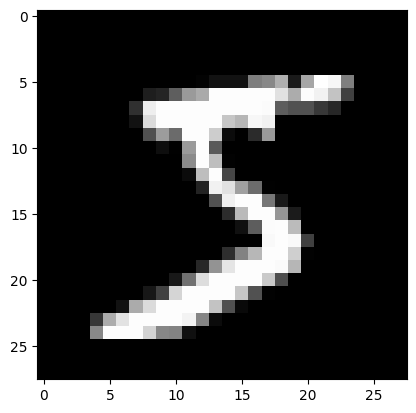

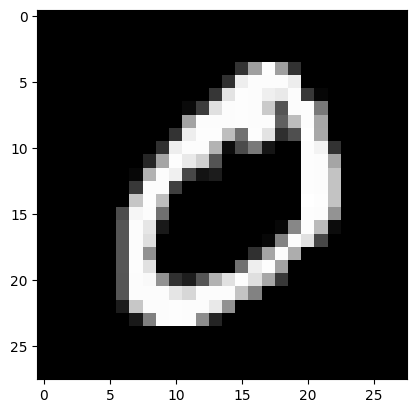

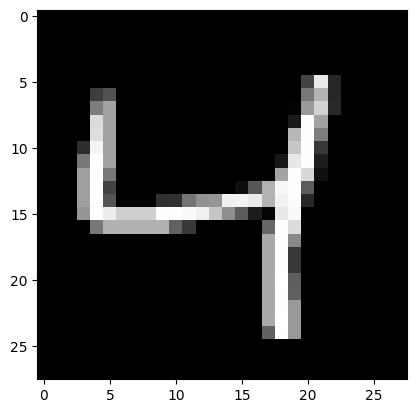

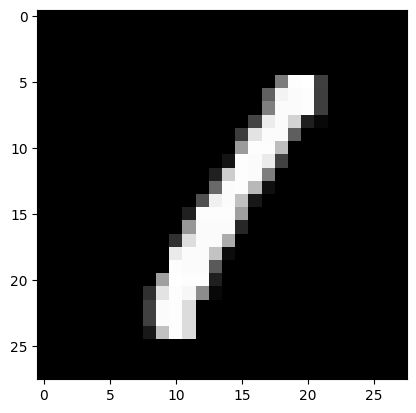

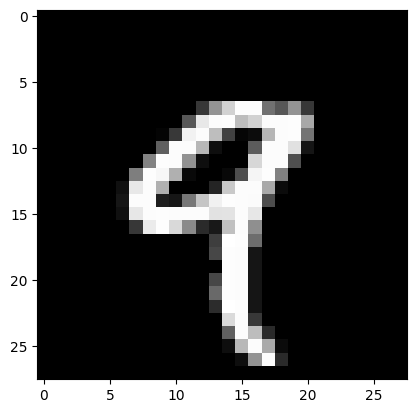

In [17]:
count = 0
for x, y in validation_dataset:
    z = model(x.reshape(-1, 28 * 28))
    _, yhat = torch.max(z, 1)
    if yhat != y:
        show_data(x)
        count += 1
    if count >= 5:
        break

## Practice: Recreate the Model with nn.Sequential 


Use <code>nn.Sequential</code> to build exactly the same model as you just built. Use the function <train>train</train> to train the model and use the function <code>plot_accuracy_loss</code> to see the metrics. Also, try different epoch numbers. 


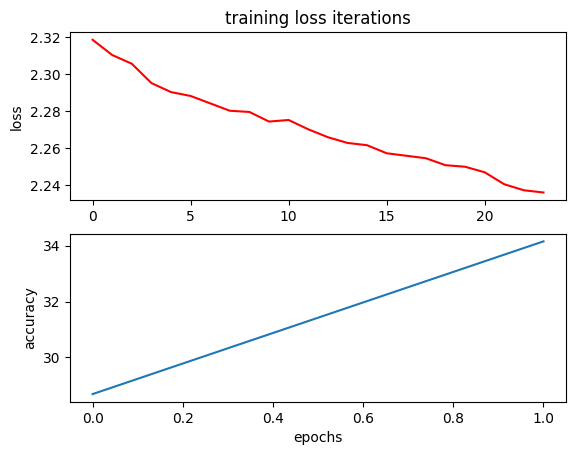

In [18]:
sequential_model = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.Sigmoid(), nn.Linear(hidden_dim, output_dim))
sequential_optimizer = torch.optim.SGD(sequential_model.parameters(), lr=0.1)
sequential_results = train(sequential_model, nn.CrossEntropyLoss(), train_loader, validation_loader, sequential_optimizer, epochs=2)
plot_accuracy_loss(sequential_results)

Double-click <b>here</b> for the solution.

<!-- 
input_dim = 28 * 28
hidden_dim = 100
output_dim = 10

model = torch.nn.Sequential(
    torch.nn.Linear(input_dim, hidden_dim),
    torch.nn.Sigmoid(),
    torch.nn.Linear(hidden_dim, output_dim),
)
learning_rate = 0.01
optimizer = torch.optim.SGD(model.parameters(), lr = learning_rate)
training_results = train(model, criterion, train_loader, validation_loader, optimizer, epochs = 10)
plot_accuracy_loss(training_results)
-->


<h2>About the Authors:</h2> 

<a href="https://www.linkedin.com/in/joseph-s-50398b136/">Joseph Santarcangelo</a> has a PhD in Electrical Engineering, his research focused on using machine learning, signal processing, and computer vision to determine how videos impact human cognition. Joseph has been working for IBM since he completed his PhD. 


Other contributors: <a href="https://www.linkedin.com/in/michelleccarey/">Michelle Carey</a>, <a href="https://www.linkedin.com/in/jiahui-mavis-zhou-a4537814a">Mavis Zhou</a>


<!--
## Change Log

|  Date (YYYY-MM-DD) |  Version | Changed By  |  Change Description |
|---|---|---|---|
| 2020-09-23  | 2.0  | Shubham  |  Migrated Lab to Markdown and added to course repo in GitLab |
-->


<hr>





## <h3 align="center"> &#169; IBM Corporation. All rights reserved. <h3/>
